In [ ]:
# ----------------------------
# Imports & Settings
# ----------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.utils import shuffle

import xgboost as xgb


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# ----------------------------
# Load dataset
# ----------------------------
df = pd.read_csv('/content/drive/MyDrive/cleaned_Final_dataset_dengu.csv')
print("Loaded dataset with shape:", df.shape)
print("Columns:", df.columns.tolist())


Loaded dataset with shape: (1529, 10)
Columns: ['Age', 'Sex', 'Hb', 'HCT', 'TC', 'PC', 'NS1', 'IgG', 'IgM', 'Severity']


In [ ]:
# ----------------------------
# Label-encode non-numeric columns
# ----------------------------
encoders = {}
for col in df.columns:
    if df[col].dtype == 'object' or df[col].dtype.name == 'category':
        le = LabelEncoder()
        df[col] = df[col].astype(str)
        df[col] = le.fit_transform(df[col])
        encoders[col] = le

print("Label-encoded columns:", list(encoders.keys()))


Label-encoded columns: ['Sex', 'NS1', 'IgG', 'IgM', 'Severity']


In [ ]:
# ----------------------------
# Helper functions
# ----------------------------
def learning_curve_by_size(model, X, y, train_fracs=None, random_state=42):
    if train_fracs is None:
        train_fracs = np.linspace(0.2, 0.9, 8)
    train_scores = []
    val_scores = []
    sizes = []
    Xs, ys = shuffle(X, y, random_state=random_state)
    n_total = len(ys)
    for frac in train_fracs:
        n_train = max(50, int(n_total * frac))
        X_sub = Xs[:n_train]
        y_sub = ys[:n_train]
        Xtr, Xval, ytr, yval = train_test_split(X_sub, y_sub, test_size=0.25, random_state=random_state, stratify=y_sub)
        model.fit(Xtr, ytr)
        ytr_pred = model.predict(Xtr)
        yval_pred = model.predict(Xval)
        train_scores.append(accuracy_score(ytr, ytr_pred))
        val_scores.append(accuracy_score(yval, yval_pred))
        sizes.append(len(Xtr))
    return sizes, train_scores, val_scores

def cv_scores_by_trees(base_model, X, y, tree_list=(50,100,200,350), cv=4):
    means = []
    stds = []
    for n in tree_list:
        model = xgb.XGBClassifier(
            n_estimators=n,
            max_depth=base_model.max_depth,
            learning_rate=0.1,
            objective='multi:softmax' if len(np.unique(y)) > 2 else 'binary:logistic',
            use_label_encoder=False,
            eval_metric='mlogloss',
            random_state=base_model.random_state,
            n_jobs=-1
        )
        scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
        means.append(scores.mean())
        stds.append(scores.std())
    return means, stds


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [05:38:52] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Test accuracy (Severity): 0.9673
              precision    recall  f1-score   support

           0     0.9785    0.9785    0.9785        93
           1     0.9703    0.9333    0.9515       105
           2     0.9554    0.9907    0.9727       108

    accuracy                         0.9673       306
   macro avg     0.9680    0.9675    0.9676       306
weighted avg     0.9675    0.9673    0.9672       306



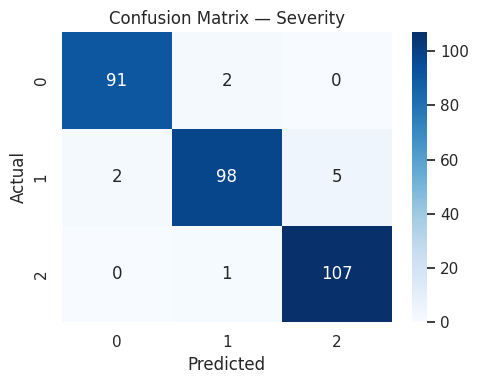


Top features — Severity:
feature  importance
    HCT    0.362023
     PC    0.314545
     Hb    0.215285
    Sex    0.035270
    Age    0.028939
    IgG    0.023372
    NS1    0.010570
     TC    0.009995


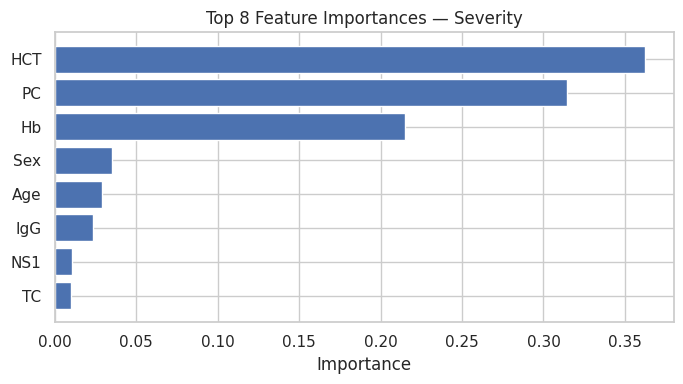

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [05:38:54] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Test accuracy (NS1): 0.8922
              precision    recall  f1-score   support

           0     0.8874    0.8933    0.8904       150
           1     0.8968    0.8910    0.8939       156

    accuracy                         0.8922       306
   macro avg     0.8921    0.8922    0.8921       306
weighted avg     0.8922    0.8922    0.8922       306



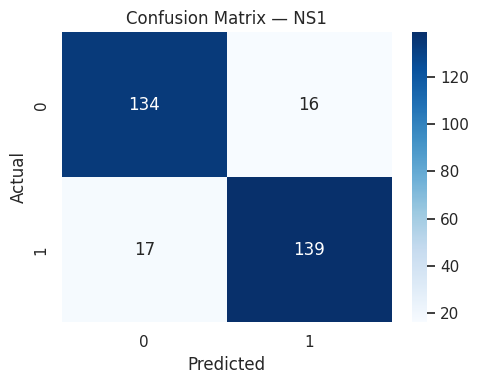


Top features — NS1:
 feature  importance
     IgG    0.161157
      PC    0.156182
      TC    0.155271
      Hb    0.129812
     Age    0.107387
     Sex    0.101026
Severity    0.100033
     HCT    0.089133


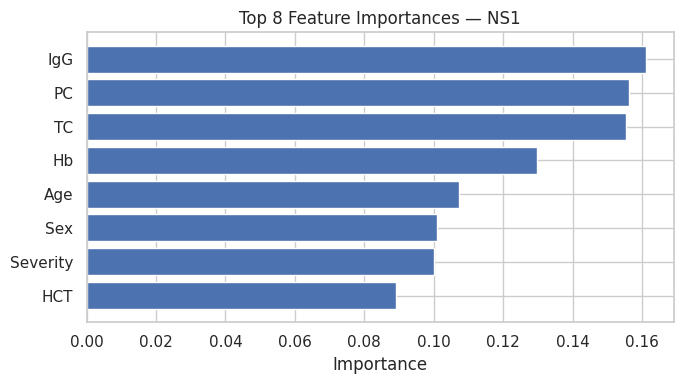

In [ ]:
for tgt in ["Severity", "NS1"]:
    df_sub = df[df[tgt].notna()].copy()
    X = df_sub.drop(columns=[tgt])
    y = df_sub[tgt].values
    unique = np.unique(y)

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                        random_state=42, stratify=y)

    # XGBoost
    xgb_model = xgb.XGBClassifier(
        n_estimators=350,
        max_depth=15,
        learning_rate=0.1,
        objective='multi:softmax' if len(unique) > 2 else 'binary:logistic',
        use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1
    )

    xgb_model.fit(X_train, y_train)
    y_pred = xgb_model.predict(X_test)

    # Accuracy
    print(f"Test accuracy ({tgt}): {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, digits=4))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix — {tgt}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

    # Feature importance
    imp_df = pd.DataFrame({
        "feature": X.columns,
        "importance": xgb_model.feature_importances_
    }).sort_values("importance", ascending=False)
    print(f"\nTop features — {tgt}:")
    print(imp_df.head(8).to_string(index=False))

    # Plot feature importance
    plt.figure(figsize=(7,4))
    plt.barh(imp_df['feature'].head(8), imp_df['importance'].head(8))
    plt.gca().invert_yaxis()
    plt.title(f"Top 8 Feature Importances — {tgt}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()


1. Imports & Settings

Import libraries: pandas, numpy, matplotlib, seaborn, sklearn, xgboost.

Set plotting style with seaborn.

2. Mount Drive & Load Dataset

Mount Google Drive in Colab to access files.

Load CSV dataset into a DataFrame df.

3. Label Encoding

Convert text/categorical columns to numbers using LabelEncoder.

Save encoders in a dictionary for reference or inverse mapping.

4. Helper Functions

Learning Curve Function: Evaluates train vs validation accuracy as training data increases.

CV Scores Function: Checks accuracy across different n_estimators using cross-validation.

5. Train & Evaluate Both Targets

Loop over Severity and NS1.

Steps for each target:

Split data into train/test sets.

Train XGBoost model.

Predict on test set.

Print accuracy & classification report.

Plot confusion matrix.

Plot top feature importance.

Plot prediction distribution.

6. Learning Curves

For each target, plot how accuracy changes with more training data.

Helps identify underfitting or overfitting.

7. CV Accuracy vs n_estimators

For each target, check how accuracy changes with different number of trees.

Plot CV accuracy vs n_estimators with error bars.

Helps choose optimal tree count.